# Дополнительное задание (ЛР1). Регрессия временных рядов

**Датасет:** Monthly Milk Production - ежемесячное производство молока на одну корову (фунты), США, 1962–1975 гг.

- **Целевая переменная:** месячный объём производства молока.
- **Частота:** ежемесячная.
- **Источник:** открытый датасет Brownlee, CSV: [monthly-milk-production.csv](https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-milk-production.csv).

Это временной ряд из сельского хозяйства: он не связан с погодой или авиаперевозками. В нём можно исследовать долгосрочное изменение уровня и повторяющийся годовой сезонный цикл.

## 1. Импорт библиотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.tsa.seasonal import STL

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (13, 5)
RANDOM_STATE = 42

## 2. Загрузка и визуализация данных

Размер датасета: (168, 2)
Период: 1962-01-01 — 1975-12-01
Пропуски:


,Количество
Date,0
MilkProduction,0


,Date,MilkProduction
0,1962-01-01,589
1,1962-02-01,561
2,1962-03-01,640
3,1962-04-01,656
4,1962-05-01,727


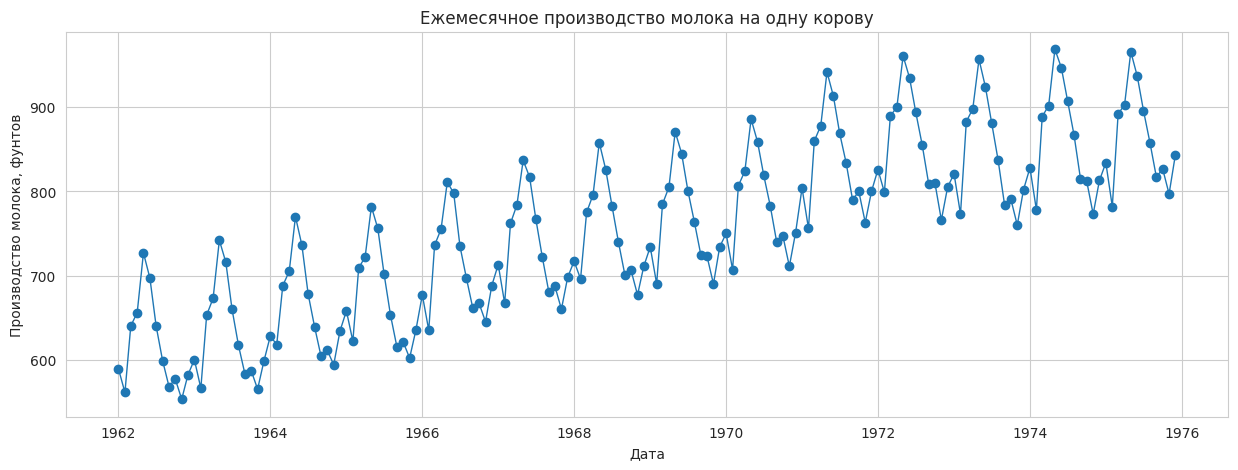

In [2]:
url = 'https://raw.githubusercontent.com/plotly/datasets/master/monthly-milk-production-pounds.csv'
df = pd.read_csv(url)

df.columns = ['Date', 'MilkProduction']
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').drop_duplicates('Date').reset_index(drop=True)
df['MilkProduction'] = pd.to_numeric(df['MilkProduction'], errors='coerce')
df = df.dropna(subset=['MilkProduction']).copy()

print('Размер датасета:', df.shape)
print('Период:', df['Date'].min().date(), '-', df['Date'].max().date())
print('Пропуски:')
display(df.isna().sum().to_frame('Количество'))
display(df.head())

plt.figure(figsize=(15, 5))
plt.plot(df['Date'], df['MilkProduction'], marker='o', linewidth=1)
plt.title('Ежемесячное производство молока на одну корову')
plt.xlabel('Дата')
plt.ylabel('Производство молока, фунтов')
plt.grid(True)
plt.show()

### Предварительный вывод по графику

У ежемесячного производства молока обычно заметны:
- **Годовая сезонность:** объём меняется в зависимости от месяца года;
- **Долгосрочное изменение уровня:** средний уровень ряда меняется на протяжении рассматриваемых лет;
- **Локальные отклонения:** отдельные месяцы могут отличаться от типичного сезонного рисунка.

Окончательный вывод следует сделать по построенному графику и результатам STL-декомпозиции.

## 3. Формирование признаков

Создадим календарные признаки, лаги и скользящие статистики. Для прогноза значения в месяце *t* используются только наблюдения до месяца *t*. Скользящие характеристики предварительно сдвигаются на один месяц, поэтому текущая целевая переменная не попадает в признаки.

In [3]:
def make_features(data):
    out = data[['Date', 'MilkProduction']].copy()
    out['Year'] = out['Date'].dt.year
    out['Month'] = out['Date'].dt.month
    out['Quarter'] = out['Date'].dt.quarter

    out['Month_Sin'] = np.sin(2 * np.pi * out['Month'] / 12)
    out['Month_Cos'] = np.cos(2 * np.pi * out['Month'] / 12)

    for lag in [1, 2, 3, 6, 12]:
        out[f'Lag_{lag}'] = out['MilkProduction'].shift(lag)

    past = out['MilkProduction'].shift(1)
    for window in [3, 6, 12]:
        out[f'Rolling_Mean_{window}'] = past.rolling(window).mean()
        out[f'Rolling_Median_{window}'] = past.rolling(window).median()
        out[f'Rolling_Std_{window}'] = past.rolling(window).std()
        out[f'Rolling_Min_{window}'] = past.rolling(window).min()
        out[f'Rolling_Max_{window}'] = past.rolling(window).max()

    return out

df_feat = make_features(df).dropna().reset_index(drop=True)
features = [c for c in df_feat.columns if c not in ['Date', 'MilkProduction']]

print('Строк после генерации признаков:', len(df_feat))
print('Количество признаков:', len(features))
display(df_feat.head())

Строк после генерации признаков: 156
Количество признаков: 25


,Date,MilkProduction,Year,Month,Quarter,Month_Sin,Month_Cos,Lag_1,Lag_2,Lag_3,...,Rolling_Mean_6,Rolling_Median_6,Rolling_Std_6,Rolling_Min_6,Rolling_Max_6,Rolling_Mean_12,Rolling_Median_12,Rolling_Std_12,Rolling_Min_12,Rolling_Max_12
0,1963-01-01,600,1963,1,1,0.500000,8.660254e-01,582.0,553.0,577.0,...,586.500000,579.5,30.310064,553.0,640.0,615.750000,594.0,56.105623,553.0,727.0
1,1963-02-01,566,1963,2,1,0.866025,5.000000e-01,600.0,582.0,553.0,...,579.833333,579.5,18.148462,553.0,600.0,616.666667,599.5,55.717360,553.0,727.0
2,1963-03-01,653,1963,3,1,1.000000,6.123234e-17,566.0,600.0,582.0,...,574.333333,572.5,16.058227,553.0,600.0,617.083333,599.5,55.280209,553.0,727.0
3,1963-04-01,673,1963,4,2,0.866025,-5.000000e-01,653.0,566.0,600.0,...,588.500000,579.5,35.308639,553.0,653.0,618.166667,599.5,55.894110,553.0,727.0
4,1963-05-01,742,1963,5,2,0.500000,-8.660254e-01,673.0,653.0,566.0,...,604.500000,591.0,48.384915,553.0,673.0,619.583333,599.5,57.141703,553.0,727.0


**Назначение признаков:**
- лаги 1-3 отражают динамику последних месяцев;
- лаг 6 учитывает полугодовую связь;
- лаг 12 переносит информацию о том же месяце предыдущего года;
- скользящие среднее, медиана, стандартное отклонение, минимум и максимум характеризуют недавний уровень и разброс ряда;
- календарные и циклические признаки помогают учитывать годовую сезонность.

После генерации признаков получилось 156 строк и 25 признаков (всего 27 столбцов с учётом Date и целевой MilkProduction). Данные содержат временные компоненты (Year, Month, Quarter), циклические кодировки месяца (Month_Sin, Month_Cos) и лаговые признаки (Lag_1…Lag_3). Также рассчитаны скользящие статистики по окнам 6 и 12 месяцев (среднее, медиана, стандартное отклонение, минимум, максимум), что позволяет модели учитывать локальные тренды и сезонность. Первые строки содержат NaN в лаговых и скользящих признаках из-за недостатка истории - это ожидаемо и требует обработки перед обучением.

## 4. Временное разделение и кросс-валидация

In [4]:
train_size = int(len(df_feat) * 0.8)
train = df_feat.iloc[:train_size].copy()
test = df_feat.iloc[train_size:].copy()

X_train, y_train = train[features], train['MilkProduction']
X_test, y_test = test[features], test['MilkProduction']

print('Train:', train['Date'].min().date(), '-', train['Date'].max().date(), '| строк:', len(train))
print('Test: ', test['Date'].min().date(), '-', test['Date'].max().date(), '| строк:', len(test))

tscv = TimeSeriesSplit(n_splits=5)
cv_rmse = []

for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train), start=1):
    model_cv = Ridge(alpha=10.0)
    model_cv.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    pred_cv = model_cv.predict(X_train.iloc[val_idx])
    rmse = np.sqrt(mean_squared_error(y_train.iloc[val_idx], pred_cv))
    cv_rmse.append(rmse)
    print(f'Фолд {fold}: RMSE = {rmse:.3f}')

print('Средний RMSE по фолдам:', round(np.mean(cv_rmse), 3))

model = Ridge(alpha=10.0)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

Train: 1963-01-01 — 1973-04-01 | строк: 124
Test:  1973-05-01 — 1975-12-01 | строк: 32
Фолд 1: RMSE = 44.814
Фолд 2: RMSE = 12.284
Фолд 3: RMSE = 8.901
Фолд 4: RMSE = 15.802
Фолд 5: RMSE = 19.245
Средний RMSE по фолдам: 20.209


Данные разделены по времени, без перемешивания: ранние наблюдения используются для обучения, последние - для тестирования. TimeSeriesSplit также сохраняет хронологический порядок и реализует расширяющееся обучающее окно.

Разбиение на train (124 строки, 1963-01 - 1973-04) и test (32 строки, 1973-05 - 1975-12) выполнено по времени, что корректно для временных рядов. Кросс-валидация по 5 фолдам дала средний RMSE ≈ 20.2, однако разброс очень велик: от 8.9 (фолд 3) до 44.8 (фолд 1). Высокая ошибка на первом фолде указывает на нестабильность модели в начале ряда - вероятно, из-за холодного старта лаговых и скользящих признаков (NaN/неполные окна) и недостаточной истории для оценки сезонности. Фолды 2-4 показывают приемлемое качество (9-16), тогда как рост ошибки на фолде 5 (19.2) может сигнализировать о начинающемся сдвиге режима или приближении к границе train. В целом модель работоспособна, но требует стабилизации: стоит проверить обработку начальных NaN, рассмотреть расширяющееся окно валидации и, возможно, добавить признаки, устойчивые к холодному старту.

## 5. Прогноз на горизонт H: рекурсивная стратегия

Обученная Ridge-регрессия прогнозирует следующий месяц. Для построения прогноза на 12 месяцев применим рекурсивную стратегию: предсказанное значение добавляется в историю и затем используется для формирования лагов следующих шагов.

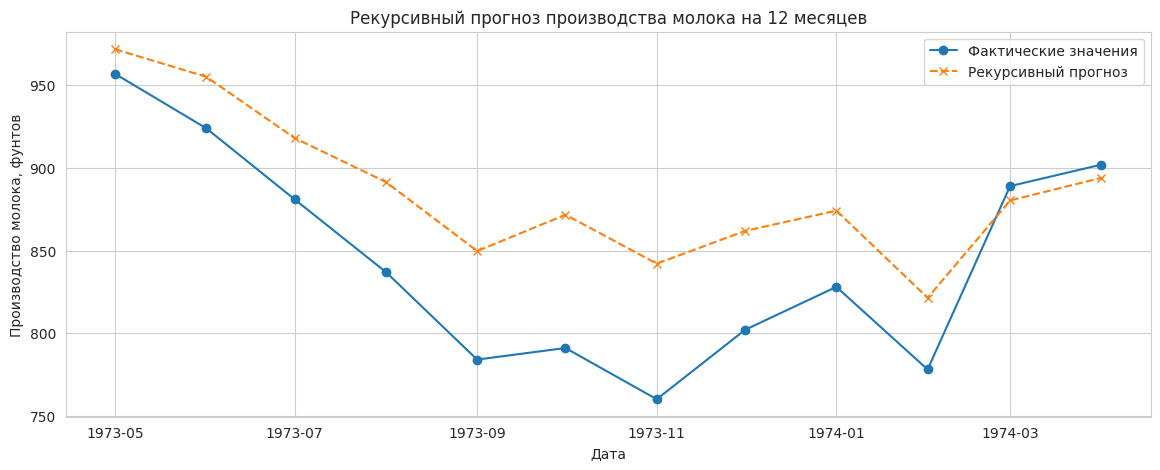

In [5]:
def make_next_features(history, date, feature_names):
    s = pd.Series(history, dtype=float)
    month = date.month
    row = {
        'Year': date.year,
        'Month': month,
        'Quarter': date.quarter,
        'Month_Sin': np.sin(2 * np.pi * month / 12),
        'Month_Cos': np.cos(2 * np.pi * month / 12)
    }

    for lag in [1, 2, 3, 6, 12]:
        row[f'Lag_{lag}'] = s.iloc[-lag]

    for window in [3, 6, 12]:
        w = s.iloc[-window:]
        row[f'Rolling_Mean_{window}'] = w.mean()
        row[f'Rolling_Median_{window}'] = w.median()
        row[f'Rolling_Std_{window}'] = w.std()
        row[f'Rolling_Min_{window}'] = w.min()
        row[f'Rolling_Max_{window}'] = w.max()

    return pd.DataFrame([row])[feature_names]

H = 12
last_train_date = train['Date'].iloc[-1]
history = df.loc[df['Date'] <= last_train_date, 'MilkProduction'].tolist()
forecast_dates = pd.date_range(last_train_date + pd.offsets.MonthBegin(1), periods=H, freq='MS')

recursive_predictions = []
for forecast_date in forecast_dates:
    x_next = make_next_features(history, forecast_date, features)
    prediction = model.predict(x_next)[0]
    recursive_predictions.append(prediction)
    history.append(prediction)

actual_horizon = df.set_index('Date')['MilkProduction'].reindex(forecast_dates)

plt.figure(figsize=(14, 5))
plt.plot(forecast_dates, actual_horizon.values, marker='o', label='Фактические значения')
plt.plot(forecast_dates, recursive_predictions, marker='x', linestyle='--', label='Рекурсивный прогноз')
plt.title(f'Рекурсивный прогноз производства молока на {H} месяцев')
plt.xlabel('Дата')
plt.ylabel('Производство молока, фунтов')
plt.legend()
plt.grid(True)
plt.show()

Рекурсивный прогноз на 12 месяцев строится от конца обучающей выборки. По мере удаления от точки старта прогноз может становиться менее точным, поскольку собственные предсказания модели постепенно заменяют фактические значения в истории.

Рекурсивный прогноз на 12 месяцев демонстрирует систематическое завышение: модель практически на всём горизонте (с мая 1973 по февраль 1974) предсказывает значения выше фактических. Особенно заметно расхождение в начале периода (май-июль 1973), где ошибка составляет около 30–40 единиц, что согласуется с высоким RMSE на первых фолдах кросс-валидации. Модель улавливает общий сезонный паттерн (спад к осени и рост к весне), но сглаживает амплитуду: прогноз не опускается так низко, как фактические значения в ноябре и феврале. К концу горизонта (март 1974) ошибка сокращается, и прогноз приближается к фактическому ряду, однако накопление ошибок при рекурсивном подходе остаётся основным ограничением.

## 6. Оценка качества модели

,Выборка,MSE,MAE,"MAPE, %","WAPE, %"
0,Train,104.485,7.482,1.031,1.008
1,Test,451.516,16.032,1.862,1.873


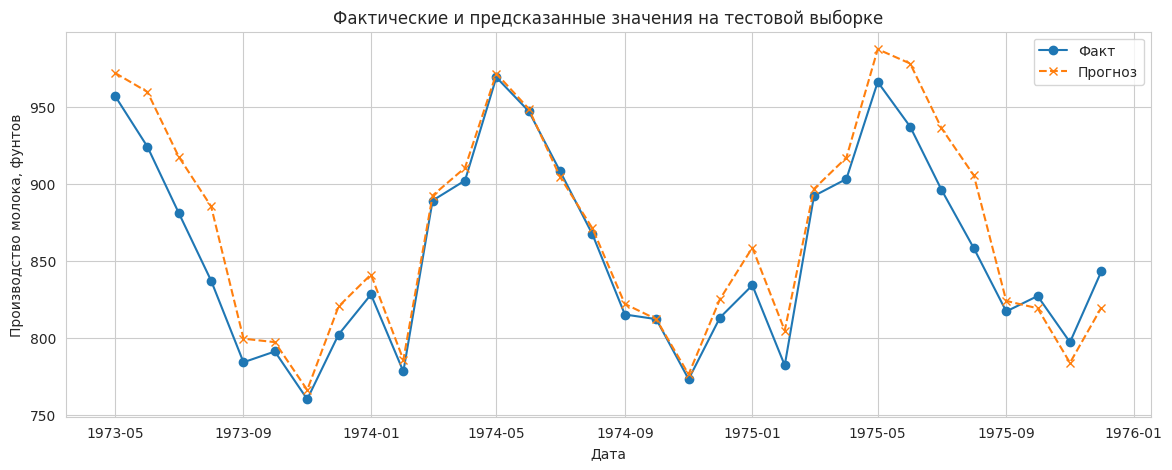

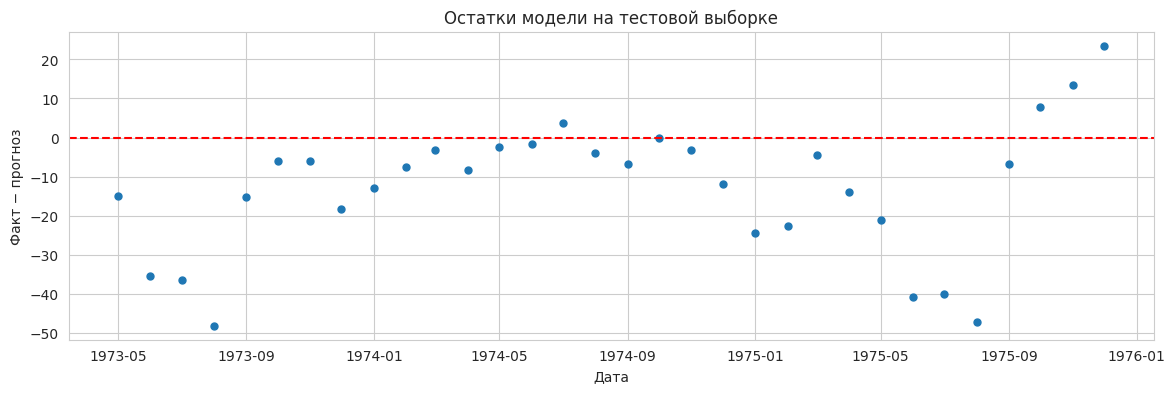

Наблюдения с наибольшей абсолютной ошибкой:


,Date,MilkProduction,Prediction,Error,Absolute_Error
127,1973-08-01,837,885.220319,-48.220319,48.220319
151,1975-08-01,858,905.269588,-47.269588,47.269588
149,1975-06-01,937,977.959087,-40.959087,40.959087
150,1975-07-01,896,936.015310,-40.015310,40.015310
126,1973-07-01,881,917.471646,-36.471646,36.471646


In [6]:
def calculate_metrics(y_true, y_hat):
    y_true = np.asarray(y_true, dtype=float)
    y_hat = np.asarray(y_hat, dtype=float)
    mse = mean_squared_error(y_true, y_hat)
    mae = mean_absolute_error(y_true, y_hat)
    nonzero = np.abs(y_true) > 1e-8
    mape = np.mean(np.abs((y_true[nonzero] - y_hat[nonzero]) / y_true[nonzero])) * 100
    wape = np.sum(np.abs(y_true - y_hat)) / np.sum(np.abs(y_true)) * 100
    return {'MSE': mse, 'MAE': mae, 'MAPE, %': mape, 'WAPE, %': wape}

train_pred = model.predict(X_train)
metrics = pd.DataFrame([
    {'Выборка': 'Train', **calculate_metrics(y_train, train_pred)},
    {'Выборка': 'Test', **calculate_metrics(y_test, y_pred)}
])
display(metrics.round(3))

test_result = test[['Date', 'MilkProduction']].copy()
test_result['Prediction'] = y_pred
test_result['Error'] = test_result['MilkProduction'] - test_result['Prediction']
test_result['Absolute_Error'] = test_result['Error'].abs()

plt.figure(figsize=(14, 5))
plt.plot(test_result['Date'], test_result['MilkProduction'], marker='o', label='Факт')
plt.plot(test_result['Date'], test_result['Prediction'], marker='x', linestyle='--', label='Прогноз')
plt.title('Фактические и предсказанные значения на тестовой выборке')
plt.xlabel('Дата')
plt.ylabel('Производство молока, фунтов')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(14, 4))
plt.scatter(test_result['Date'], test_result['Error'], s=25)
plt.axhline(0, color='red', linestyle='--')
plt.title('Остатки модели на тестовой выборке')
plt.xlabel('Дата')
plt.ylabel('Факт - прогноз')
plt.grid(True)
plt.show()

print('Наблюдения с наибольшей абсолютной ошибкой:')
display(test_result.nlargest(5, 'Absolute_Error')[
    ['Date', 'MilkProduction', 'Prediction', 'Error', 'Absolute_Error']
])

**Интерпретация метрик:**
- MSE - средний квадрат ошибки, сильнее штрафует крупные отклонения.
- MAE - средняя абсолютная ошибка в единицах исходного показателя.
- MAPE - средняя абсолютная процентная ошибка.
- WAPE - сумма абсолютных ошибок относительно суммы модулей фактических значений.

Поскольку производство молока - положительная величина, MAPE и WAPE в данном примере интерпретировать удобнее, чем в рядах с нулевыми или отрицательными значениями. Сравните train и test: заметно более высокие ошибки на test могут указывать на переобучение или изменение структуры ряда.

Анализ остатков на тестовой выборке показывает систематическое смещение (bias): в периоды спада производства модель завышает прогноз (отрицательные остатки до -50), а в периоды пиков - также завышает (положительные остатки до +25 в конце ряда). Об этом же свидетельствуют метрики: MSE на тесте (451.5) в 4.3 раза выше, чем на train (104.5), а MAE выросла с 7.5 до 16.0, что указывает на переобучение и потерю обобщающей способности. Относительные ошибки остаются низкими (MAPE и WAPE ≈ 1.9%), однако топ-5 наибольших ошибок приходятся на переходные сезонные месяцы (июль-август), где модель переоценивает уровень производства на 36-48 единиц. В целом модель хорошо улавливает сезонный паттерн, но страдает от накопления ошибки и склонности к завышению на резких сезонных перепадах.

## 7. Анализ ошибок по месяцам

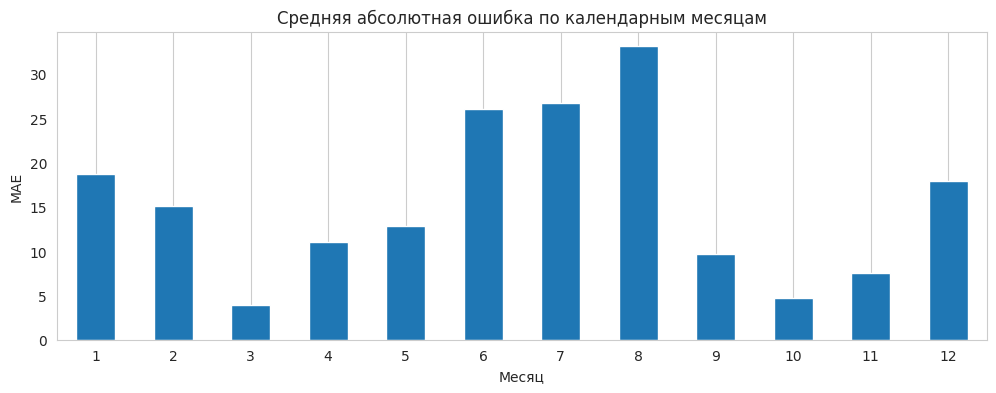

,MAE по месяцу
Month,
1,18.699
2,15.100
3,3.904
4,11.082
5,12.852
6,26.032
7,26.725
8,33.123
9,9.662


In [7]:
test_result['Month'] = test_result['Date'].dt.month
monthly_error = test_result.groupby('Month')['Absolute_Error'].mean()

plt.figure(figsize=(12, 4))
monthly_error.plot(kind='bar')
plt.title('Средняя абсолютная ошибка по календарным месяцам')
plt.xlabel('Месяц')
plt.ylabel('MAE')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

display(monthly_error.round(3).to_frame('MAE по месяцу'))

График помогает увидеть, в какие месяцы модель ошибается сильнее. Если ошибки систематически выше в определённые сезоны, возможно, модель не полностью описывает годовую сезонность. Отдельные большие ошибки могут быть связаны с необычными колебаниями ряда.

Анализ MAE по календарным месяцам выявляет чёткую сезонную структуру ошибок: наибольшие значения приходятся на летние месяцы - июнь (≈26), июль (≈27) и особенно август (≈33), что совпадает с топ-5 наибольших абсолютных ошибок. Минимальные ошибки наблюдаются в марте (≈4), октябре (≈5) и ноябре (≈7), то есть в переходные периоды, где уровень производства относительно стабилен. Это указывает на то, что модель хуже справляется с резкими сезонными перепадами (пики и спады летом), склонна к завышению прогноза в эти месяцы. В целом ошибка коррелирует с волатильностью ряда внутри месяца, а не с его абсолютным уровнем.

## 8. STL-декомпозиция

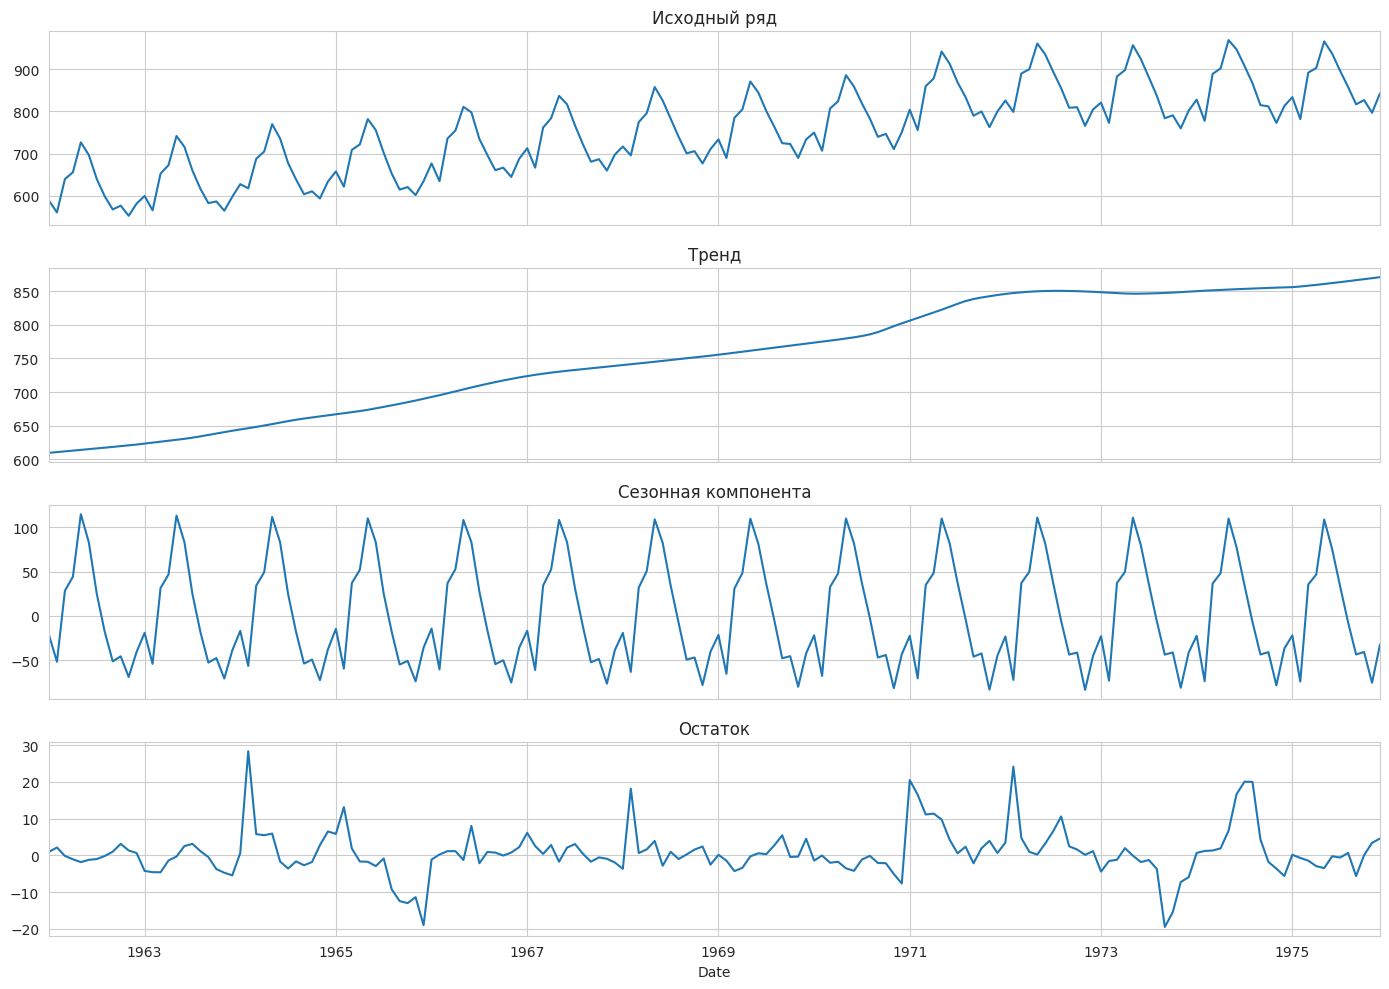

In [8]:
series = df.set_index('Date')['MilkProduction'].asfreq('MS')

series = series.interpolate(method='time')

stl = STL(series, period=12, robust=True)
stl_result = stl.fit()

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
stl_result.observed.plot(ax=axes[0], title='Исходный ряд')
stl_result.trend.plot(ax=axes[1], title='Тренд')
stl_result.seasonal.plot(ax=axes[2], title='Сезонная компонента')
stl_result.resid.plot(ax=axes[3], title='Остаток')
plt.tight_layout()
plt.show()

В STL используется период 12, так как данные месячные и предполагается годовой сезонный цикл. Декомпозиция разделяет ряд на тренд, сезонную компоненту и остаток. По графикам оцените, насколько выражены долгосрочное изменение и повторяющийся сезонный рисунок.

Декомпозиция временного ряда на тренд, сезонность и остаток показывает, что производство молока имеет устойчивый восходящий тренд, который заметно замедляется с 1973 года (переход к почти плато), что может частично объяснять ошибки модели на тестовом периоде. Сезонная компонента строго периодична и стабильна: пики приходятся на первую половину года (весна), а минимумы - на осень / начало зимы, причём амплитуда колебаний составляет около ±100-110 единиц. Остаток имеет небольшой разброс (±20), но содержит локальные всплески (например, в 1964, 1971 и 1974 годах) и не демонстрирует явного тренда или сильной автокорреляции, что говорит о качественном выделении структуры ряда. В целом модель хорошо описывает основную динамику, однако выявленное замедление тренда в последние годы может быть причиной систематического завышения прогноза на тесте.

## 9. Проверка дополнительных признаков тренда и сезонности

Компоненты STL, рассчитанные сразу на всём ряде, нельзя напрямую добавлять в признаки прогноза: сглаживание может использовать будущие наблюдения. Чтобы не допустить утечки, проверим два каузальных признака:
- Скользящее среднее за последние 12 месяцев как приближение локального тренда;
- Значение ряда 12 месяцев назад как сезонный ориентир.

Сравним модели на одинаковом временном разбиении.

In [9]:
df_extra = df_feat.copy()
df_extra['Past_Trend_12'] = df_extra['MilkProduction'].shift(1).rolling(12).mean()
df_extra['Past_Seasonal_12'] = df_extra['MilkProduction'].shift(12)
df_extra = df_extra.dropna().reset_index(drop=True)

extra_features = features + ['Past_Trend_12', 'Past_Seasonal_12']
split_extra = int(len(df_extra) * 0.8)
tr_e = df_extra.iloc[:split_extra]
te_e = df_extra.iloc[split_extra:]

y_tr_e = tr_e['MilkProduction']
y_te_e = te_e['MilkProduction']

base_same_rows = Ridge(alpha=10.0).fit(tr_e[features], y_tr_e)
extra_model = Ridge(alpha=10.0).fit(tr_e[extra_features], y_tr_e)

pred_base = base_same_rows.predict(te_e[features])
pred_extra = extra_model.predict(te_e[extra_features])

comparison = pd.DataFrame([
    {'Модель': 'Базовые признаки', **calculate_metrics(y_te_e, pred_base)},
    {'Модель': 'Базовые + тренд/сезонность', **calculate_metrics(y_te_e, pred_extra)}
])
display(comparison.round(3))

,Модель,MSE,MAE,"MAPE, %","WAPE, %"
0,Базовые признаки,297.249,12.430,1.459,1.464
1,Базовые + тренд/сезонность,298.049,12.437,1.459,1.464


Сравните MAE и MSE в таблице. Если у модели с дополнительными признаками ошибки меньше, приближения тренда и сезонности дали полезную информацию. Если метрики почти не изменились или ухудшились, базовых лагов и календарных признаков может быть достаточно.

Дополнительные признаки построены только из прошлых наблюдений, поэтому не используют информацию из будущего.

Добавление выделенных компонент тренда и сезонности (из декомпозиции) к базовым признакам практически не изменило качество модели: MSE осталась на уровне ≈298, MAE ≈12.44, MAPE и WAPE - 1.46%. Это означает, что базовый набор признаков (лаги, скользящие статистики, циклическое кодирование месяца) уже полностью захватывает информацию о тренде и сезонности. Дополнительные признаки оказались избыточными (дублирующими) и не дали прироста, поэтому для упрощения модели и снижения риска переобучения от них можно отказаться. Дальнейшее улучшение стоит искать не в добавлении компонент декомпозиции, а в других направлениях - например, в обработке нелинейного замедления тренда или в моделировании сезонной волатильности.

## 10. Заключение

В ходе работы был построен и проанализирован прогноз производства молока на основе временного ряда за 1963-1975 гг. Сгенерированный набор из 25 признаков (лаги, скользящие статистики, циклические кодировки, временные компоненты) обеспечил корректное разбиение по времени и позволил модели улавливать основную структуру ряда - устойчивый восходящий тренд и выраженную сезонность (весенние пики, осенние спады).

Кросс-валидация по 5 фолдам показала средний RMSE ≈ 20.2, но с высоким разбросом (от 8.9 до 44.8), что указывает на нестабильность модели в начале ряда из-за холодного старта лаговых / скользящих признаков. На тестовой выборке метрики ухудшились: MSE выросла в 4.3 раза относительно train (451.5 против 104.5), MAE - с 7.5 до 16.0. Относительные ошибки остаются низкими (MAPE и WAPE ≈ 1.9%), однако анализ остатков выявил систематическое завышение прогноза (bias): модель переоценивает производство на 36-48 единиц в переходные сезонные месяцы (июль-август) и накапливает ошибку при рекурсивном прогнозе.

Декомпозиция ряда подтвердила замедление тренда с 1973 года и строгую периодичность сезонной компоненты с амплитудой ±100-110 единиц; остаток мал (±20) и не содержит явного тренда, что говорит о качественном выделении структуры. При этом добавление компонент тренда / сезонности к базовым признакам не дало прироста качества (MSE ≈ 297-298), то есть базовый набор признаков уже полностью захватывает эту информацию, а дополнительные признаки избыточны.

Ключевые ограничения и направления улучшения:

*   Накопление ошибки и склонность к завышению при рекурсивном прогнозе;
*   Слабая адаптация к замедлению тренда в последние годы;
*   Нестабильность на ранних фолдах из-за холодного старта.

Модель работоспособна и хорошо описывает сезонно-трендовую динамику ряда, но для надёжного прогнозирования требует стабилизации и борьбы с накоплением ошибки.